# Retail Sales Profitability Analysis

**Goal:** find where this store makes and loses money, and what drives the losses.

**Data:** 9,994 sales records (the Sample Superstore dataset, US retail).
It is one flat table: no order id, dates or product names, so the analysis works at category,
sub-category, region and state level.

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 150)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_rows", 60)
os.makedirs("../images", exist_ok=True)

In [2]:
df = pd.read_csv("../data/SampleSuperstore.csv")

# lowercase column names with underscores
df.columns = [c.strip().lower().replace(" ", "_").replace("-", "_") for c in df.columns]

print(df.shape)
df.head()

(9994, 13)


,ship_mode,segment,country,city,state,postal_code,region,category,sub_category,sales,quantity,discount,profit
0,Second Class,Consumer,United States,Henderson,Kentucky,42420,South,Furniture,Bookcases,261.9600,2,0.00,41.9136
1,Second Class,Consumer,United States,Henderson,Kentucky,42420,South,Furniture,Chairs,731.9400,3,0.00,219.5820
2,Second Class,Corporate,United States,Los Angeles,California,90036,West,Office Supplies,Labels,14.6200,2,0.00,6.8714
3,Standard Class,Consumer,United States,Fort Lauderdale,Florida,33311,South,Furniture,Tables,957.5775,5,0.45,-383.0310
4,Standard Class,Consumer,United States,Fort Lauderdale,Florida,33311,South,Office Supplies,Storage,22.3680,2,0.20,2.5164


## 1. Check the data

In [3]:
print("Missing values:", df.isna().sum().sum())
print("Exact duplicate rows:", df.duplicated().sum())
df[["sales", "quantity", "discount", "profit"]].describe().round(2)

Missing values: 0
Exact duplicate rows: 17


,sales,quantity,discount,profit
count,9994.00,9994.00,9994.00,9994.00
mean,229.86,3.79,0.16,28.66
std,623.25,2.23,0.21,234.26
min,0.44,1.00,0.00,-6599.98
25%,17.28,2.00,0.00,1.73
50%,54.49,3.00,0.20,8.67
75%,209.94,5.00,0.20,29.36
max,22638.48,14.00,0.80,8399.98


There are 17 exact duplicate rows. With no order id, they could be real repeat purchases, so they are kept.
Dropping them changes total profit from $286,397 to $286,241, which is too small to matter.

In [4]:
total_sales = df.sales.sum()
total_profit = df.profit.sum()

def margin(data):
    # margin = total profit / total sales (never the average of row margins)
    return data.profit.sum() / data.sales.sum() * 100

def summarize(column):
    table = df.groupby(column).agg(
        records=("sales", "size"),
        sales=("sales", "sum"),
        profit=("profit", "sum"),
        avg_discount=("discount", "mean"),
    )
    table["margin_pct"] = (table.profit / table.sales * 100).round(2)
    table["profit_share_pct"] = (table.profit / total_profit * 100).round(1)
    table[["sales", "profit"]] = table[["sales", "profit"]].round(0)
    table["avg_discount"] = table.avg_discount.round(3)
    return table.sort_values("profit", ascending=False)

## 2. Overall

In [5]:
losses = df[df.profit < 0]
print(f"Records: {len(df):,}")
print(f"Sales: ${total_sales:,.0f}   Profit: ${total_profit:,.0f}   Margin: {margin(df):.2f}%")
print(f"Loss-making records: {len(losses):,} ({len(losses) / len(df) * 100:.1f}%), total loss ${-losses.profit.sum():,.0f}")

Records: 9,994
Sales: $2,297,201   Profit: $286,397   Margin: 12.47%
Loss-making records: 1,871 (18.7%), total loss $156,131


## 3. Category and sub-category

In [6]:
summarize("category")

,records,sales,profit,avg_discount,margin_pct,profit_share_pct
category,,,,,,
Technology,1847,836154.0,145455.0,0.132,17.40,50.8
Office Supplies,6026,719047.0,122491.0,0.157,17.04,42.8
Furniture,2121,742000.0,18451.0,0.174,2.49,6.4


In [7]:
sub = summarize("sub_category")
sub

,records,sales,profit,avg_discount,margin_pct,profit_share_pct
sub_category,,,,,,
Copiers,68,149528.0,55618.0,0.162,37.20,19.4
Phones,889,330007.0,44516.0,0.155,13.49,15.5
Accessories,775,167380.0,41937.0,0.078,25.05,14.6
Paper,1370,78479.0,34054.0,0.075,43.39,11.9
Binders,1523,203413.0,30222.0,0.372,14.86,10.6
Chairs,617,328449.0,26590.0,0.170,8.10,9.3
Storage,846,223844.0,21279.0,0.075,9.51,7.4
Appliances,466,107532.0,18138.0,0.167,16.87,6.3
Furnishings,957,91705.0,13059.0,0.138,14.24,4.6


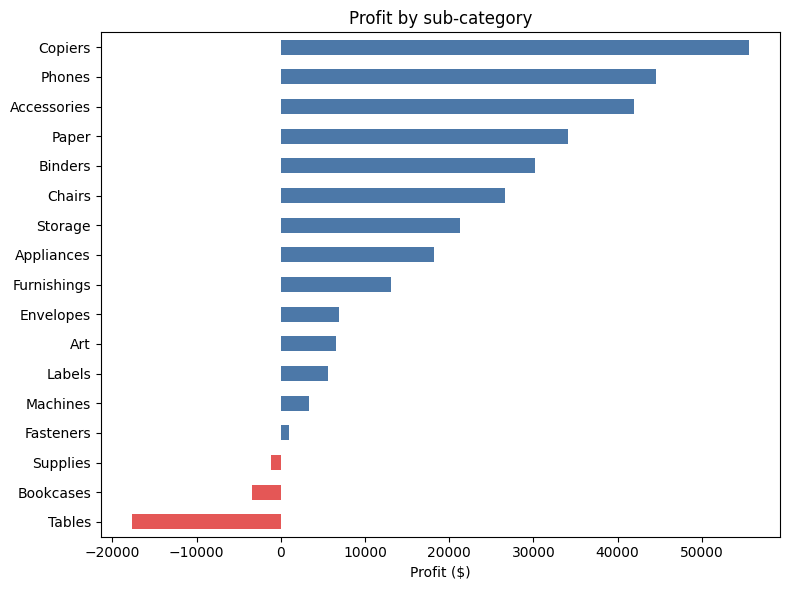

In [8]:
colors = ["#E45756" if p < 0 else "#4C78A8" for p in sub.profit.sort_values()]
ax = sub.profit.sort_values().plot(kind="barh", color=colors, figsize=(8, 6))
ax.set_title("Profit by sub-category")
ax.set_xlabel("Profit ($)")
ax.set_ylabel("")
plt.tight_layout()
plt.savefig("../images/profit_by_subcategory.png", dpi=150)
plt.show()

Furniture is 32% of sales but only 6.4% of profit (margin 2.49%),
while Technology (17.4%) and Office Supplies (17.0%) earn the rest.
Only three sub-categories lose money: Tables (-8.6%), Bookcases (-3.0%) and Supplies (-2.5%).

## 4. Discounts
Discount is the first thing to check for losses. Profit by discount band:

In [9]:
bands = pd.cut(df.discount, [-0.001, 0, 0.1, 0.2, 0.3, 0.5, 0.81],
               labels=["0%", "1-10%", "11-20%", "21-30%", "31-50%", "51-80%"])

by_band = df.groupby(bands, observed=True).agg(
    records=("sales", "size"),
    sales=("sales", "sum"),
    profit=("profit", "sum"),
    loss_making_pct=("profit", lambda x: round((x < 0).mean() * 100, 1)),
)
by_band["margin_pct"] = (by_band.profit / by_band.sales * 100).round(1)
by_band[["sales", "profit"]] = by_band[["sales", "profit"]].round(0)
by_band

,records,sales,profit,loss_making_pct,margin_pct
discount,,,,,
0%,4798,1087908.0,320988.0,0.0,29.5
1-10%,94,54369.0,9029.0,4.3,16.6
11-20%,3709,792153.0,91756.0,14.0,11.6
21-30%,227,103227.0,-10369.0,91.6,-10.0
31-50%,310,195315.0,-48448.0,91.6,-24.8
51-80%,856,64229.0,-76559.0,100.0,-119.2


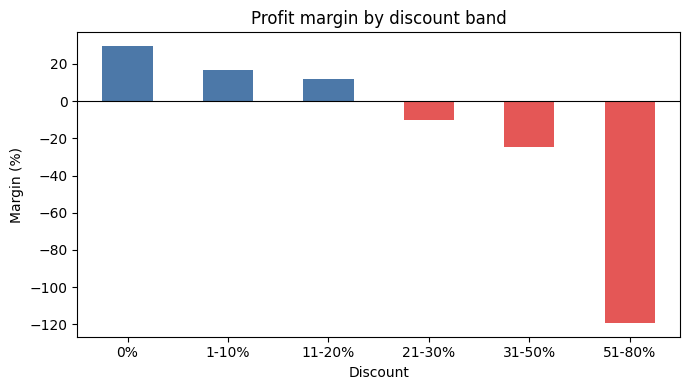

In [10]:
ax = by_band.margin_pct.plot(kind="bar", color=["#4C78A8" if m >= 0 else "#E45756" for m in by_band.margin_pct],
                             rot=0, figsize=(7, 4))
ax.set_title("Profit margin by discount band")
ax.set_ylabel("Margin (%)")
ax.set_xlabel("Discount")
ax.axhline(0, color="black", linewidth=0.8)
plt.tight_layout()
plt.savefig("../images/margin_by_discount_band.png", dpi=150)
plt.show()

In [11]:
deep = df[df.discount > 0.2]
normal = df[df.discount <= 0.2]

print(f"Discount above 20%: {len(deep):,} records ({len(deep) / len(df) * 100:.1f}%), "
      f"profit -${-deep.profit.sum():,.0f}, margin {margin(deep):.1f}%")
print(f"Discount 20% or less: {len(normal):,} records, profit ${normal.profit.sum():,.0f}, margin {margin(normal):.1f}%")

loss_from_deep = losses[losses.discount > 0.2].profit.sum() / losses.profit.sum() * 100
print(f"Share of all loss dollars that comes from discounts above 20%: {loss_from_deep:.1f}%")

Discount above 20%: 1,393 records (13.9%), profit -$135,376, margin -37.3%
Discount 20% or less: 8,601 records, profit $421,773, margin 21.8%
Share of all loss dollars that comes from discounts above 20%: 88.7%


The 11 to 20% band still earns 11.6%, but the 21 to 30% band drops to -10.0% with 92% of its records losing money.
Records with a discount above 20% are 13.9% of the data, lost **$135K** (margin -37.3%),
and cause **88.7%** of all loss dollars. Records at 20% or less earn 21.8%.

## 5. Are the loss-making sub-categories bad products, or badly discounted?

In [12]:
df["deep_discount"] = df.discount > 0.2

split = df[df.sub_category.isin(["Tables", "Bookcases", "Supplies"])].groupby(
    ["sub_category", "deep_discount"]
).agg(records=("sales", "size"), sales=("sales", "sum"), profit=("profit", "sum"))
split["margin_pct"] = (split.profit / split.sales * 100).round(1)
split[["sales", "profit"]] = split[["sales", "profit"]].round(0)
split

records     sales   profit  margin_pct
sub_category deep_discount                                        
Bookcases    False              158   86336.0   7625.0         8.8
             True                70   28544.0 -11098.0       -38.9
Supplies     False              190   46674.0  -1189.0        -2.5
Tables       False              143  117009.0  12973.0        11.1
             True               176   89957.0 -30698.0       -34.1

Tables earn about 11% at normal discounts but -34% under deep discounts. Bookcases go from about 9% to -39%.
So for these two, the **discounting** is the problem, not the product.
Supplies is different: it loses money even at low discounts (average discount only 7.7%),
so a discount cap would not fix it. That looks like a cost or pricing problem.

## 6. Region and state

In [13]:
summarize("region")

,records,sales,profit,avg_discount,margin_pct,profit_share_pct
region,,,,,,
West,3203,725458.0,108418.0,0.109,14.94,37.9
East,2848,678781.0,91523.0,0.145,13.48,32.0
South,1620,391722.0,46749.0,0.147,11.93,16.3
Central,2323,501240.0,39706.0,0.240,7.92,13.9


In [14]:
pivot = df.pivot_table(index="region", columns="category", values=["profit", "sales"], aggfunc="sum")
print("Margin (%) by region and category")
print((pivot["profit"] / pivot["sales"] * 100).round(1))
print()
print("Average discount by region and category")
print(df.pivot_table(index="region", columns="category", values="discount", aggfunc="mean").round(3))

Margin (%) by region and category
category  Furniture  Office Supplies  Technology
region                                          
Central        -1.8              5.3        19.8
East            1.5             20.0        17.9
South           5.8             15.9        13.4
West            4.6             23.8        17.6

Average discount by region and category
category  Furniture  Office Supplies  Technology
region                                          
Central       0.297            0.253       0.133
East          0.154            0.143       0.143
South         0.122            0.167       0.108
West          0.131            0.093       0.134


In [15]:
states = summarize("state")
losing_states = states[states.profit < 0].sort_values("profit")
print(f"States with a net loss: {len(losing_states)} of {len(states)}, total loss ${-losing_states.profit.sum():,.0f}")
losing_states

States with a net loss: 10 of 49, total loss $98,246


,records,sales,profit,avg_discount,margin_pct,profit_share_pct
state,,,,,,
Texas,985,170188.0,-25729.0,0.370,-15.12,-9.0
Ohio,469,78258.0,-16971.0,0.325,-21.69,-5.9
Pennsylvania,587,116512.0,-15560.0,0.329,-13.35,-5.4
Illinois,492,80166.0,-12608.0,0.390,-15.73,-4.4
North Carolina,249,55603.0,-7491.0,0.284,-13.47,-2.6
Colorado,182,32108.0,-6528.0,0.316,-20.33,-2.3
Tennessee,183,30662.0,-5342.0,0.291,-17.42,-1.9
Arizona,224,35282.0,-3428.0,0.304,-9.72,-1.2
Florida,383,89474.0,-3399.0,0.299,-3.80,-1.2


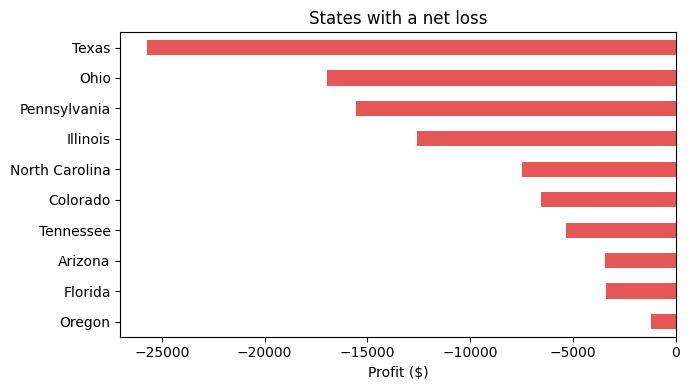

In [16]:
ax = losing_states.profit.sort_values(ascending=False).plot(kind="barh", color="#E45756", figsize=(7, 4))
ax.set_title("States with a net loss")
ax.set_xlabel("Profit ($)")
ax.set_ylabel("")
plt.tight_layout()
plt.savefig("../images/loss_making_states.png", dpi=150)
plt.show()

The Central region earns 7.9% against 14.9% in the West, with average discounts of 24.0% against 10.9%.
Central Furniture runs at -1.8%.
10 of 49 states lose money, $98.2K combined, led by Texas, Ohio, Pennsylvania, Illinois.
Texas lost $25.7K with an average discount of 37%, against 7.3% in California and 5.5% in New York.

## 7. What if the deep-discount sales had never happened?

In [17]:
profit_without = normal.profit.sum()
print(f"Actual profit: ${total_profit:,.0f}")
print(f"Profit without the deep-discount sales: ${profit_without:,.0f}")
print(f"Change: {(profit_without - total_profit) / total_profit * 100:+.1f}%")

Actual profit: $286,397
Profit without the deep-discount sales: $421,773
Change: +47.3%


Even walking away from every sale discounted above 20% would have raised profit from $286,397 to $421,773 (+47.3%).
This ignores side effects such as lost customers or lost cross-sales, so treat it as a rough size of the problem, not a forecast.

## Summary

| Finding | Number |
|---|---|
| Sales / profit / margin | $2.30M / $286K / 12.5% |
| Loss-making records | 18.7% ($156K total loss) |
| Furniture | 32% of sales, 6.4% of profit (2.49% margin) |
| Loss-making sub-categories | Tables, Bookcases, Supplies |
| Discounts above 20% | 13.9% of records, $135K loss, 88.7% of all loss dollars |
| Margin at 20% discount or less | 21.8% |
| States with a net loss | 10 of 49 ($98.2K combined) |

**Ideas to test (not proven):** cap discounts at 20%, review pricing and costs for Supplies, and review discount practice in Central Furniture and in the losing states.

**Limits:** the data has no dates, order ids or product names, so there is no trend, order-level or product-level analysis. Discounts may have been given to items that were already selling badly, so a discount can be a symptom as well as a cause.